In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px


In [2]:
df1 = pd.read_csv("data/mexico-real-estate-1.csv")
df2 = pd.read_csv("data/mexico-real-estate-2.csv")
df3 = pd.read_csv("data/mexico-real-estate-3.csv")

print("df1 shape:", df1.shape)
print("df2 shape:", df2.shape)
print("df3 shape:", df3.shape)


df1 shape: (700, 6)
df2 shape: (700, 6)
df3 shape: (700, 5)


In [3]:
df1.info()
df1.head()

<class 'pandas.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   property_type  700 non-null    str    
 1   state          700 non-null    str    
 2   lat            583 non-null    float64
 3   lon            583 non-null    float64
 4   area_m2        700 non-null    float64
 5   price_usd      700 non-null    str    
dtypes: float64(3), str(3)
memory usage: 32.9 KB


,property_type,state,lat,lon,area_m2,price_usd
0,house,Estado de México,19.560181,-99.233528,150.0,"$67,965.56"
1,house,Nuevo León,25.688436,-100.198807,186.0,"$63,223.78"
2,apartment,Guerrero,16.767704,-99.764383,82.0,"$84,298.37"
3,apartment,Guerrero,16.829782,-99.911012,150.0,"$94,308.80"
4,house,Veracruz de Ignacio de la Llave,NaN,NaN,175.0,"$94,835.67"


In [4]:
# Drop null values from df1
df1.dropna(inplace=True)

# Clean "price_usd" column in df1
df1["price_usd"] = df1["price_usd"].str.replace("$","",regex=False).str.replace(",","",regex=False).astype(float)

print("df1 shape:", df1.shape)
df1.info()
df1.head()

df1 shape: (583, 6)
<class 'pandas.DataFrame'>
Index: 583 entries, 0 to 699
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   property_type  583 non-null    str    
 1   state          583 non-null    str    
 2   lat            583 non-null    float64
 3   lon            583 non-null    float64
 4   area_m2        583 non-null    float64
 5   price_usd      583 non-null    float64
dtypes: float64(4), str(2)
memory usage: 31.9 KB


,property_type,state,lat,lon,area_m2,price_usd
0,house,Estado de México,19.560181,-99.233528,150.0,67965.56
1,house,Nuevo León,25.688436,-100.198807,186.0,63223.78
2,apartment,Guerrero,16.767704,-99.764383,82.0,84298.37
3,apartment,Guerrero,16.829782,-99.911012,150.0,94308.80
5,house,Yucatán,21.052583,-89.538639,205.0,105191.37


In [5]:
df2.info()
df2.head()

<class 'pandas.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   property_type  700 non-null    str    
 1   state          700 non-null    str    
 2   lat            571 non-null    float64
 3   lon            571 non-null    float64
 4   area_m2        700 non-null    float64
 5   price_mxn      700 non-null    float64
dtypes: float64(4), str(2)
memory usage: 32.9 KB


,property_type,state,lat,lon,area_m2,price_mxn
0,apartment,Nuevo León,25.721081,-100.345581,72.0,1300000.0
1,apartment,Puebla,NaN,NaN,190.0,2500000.0
2,house,Morelos,23.634501,-102.552788,360.0,5300000.0
3,house,Morelos,NaN,NaN,76.0,820000.0
4,house,Puebla,NaN,NaN,200.0,1100000.0


In [6]:
# Drop null values from df2
df2.dropna(inplace=True)

# Create "price_usd" column for df2 (19 pesos to the dollar in 2014)
df2["price_usd"] = (df2["price_mxn"]/19).round(2)

# Drop "price_mxn" column from df2
df2.drop(columns=["price_mxn"],inplace=True)

df2.info()
df2.head()

<class 'pandas.DataFrame'>
Index: 571 entries, 0 to 699
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   property_type  571 non-null    str    
 1   state          571 non-null    str    
 2   lat            571 non-null    float64
 3   lon            571 non-null    float64
 4   area_m2        571 non-null    float64
 5   price_usd      571 non-null    float64
dtypes: float64(4), str(2)
memory usage: 31.2 KB


,property_type,state,lat,lon,area_m2,price_usd
0,apartment,Nuevo León,25.721081,-100.345581,72.0,68421.05
2,house,Morelos,23.634501,-102.552788,360.0,278947.37
6,apartment,Estado de México,19.272040,-99.572013,85.0,65789.47
7,house,San Luis Potosí,22.138882,-100.996510,158.0,111578.95
8,apartment,Distrito Federal,19.394558,-99.129707,65.0,39904.74


In [7]:
df3.info()
df3.head()

<class 'pandas.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   property_type            700 non-null    str    
 1   place_with_parent_names  700 non-null    str    
 2   lat-lon                  582 non-null    str    
 3   area_m2                  700 non-null    float64
 4   price_usd                700 non-null    float64
dtypes: float64(2), str(3)
memory usage: 27.5 KB


,property_type,place_with_parent_names,lat-lon,area_m2,price_usd
0,apartment,|México|Distrito Federal|Gustavo A. Madero|Acu...,"19.52589,-99.151703",71.0,48550.59
1,house,|México|Estado de México|Toluca|Metepec|,"19.2640539,-99.5727534",233.0,168636.73
2,house,|México|Estado de México|Toluca|Toluca de Lerd...,"19.268629,-99.671722",300.0,86932.69
3,house,|México|Morelos|Temixco|Burgos Bugambilias|,NaN,275.0,263432.41
4,apartment,|México|Veracruz de Ignacio de la Llave|Veracruz|,"19.511938,-96.871956",84.0,68508.67


In [8]:
# Drop null values from df3
df3.dropna(inplace=True)

# Create "lat" and "lon" columns for df3
df3[["lat", "lon"]] = df3["lat-lon"].str.split(",",expand=True).astype(float)

# Print object type, shape, and head
df3.info()
df3.head()

<class 'pandas.DataFrame'>
Index: 582 entries, 0 to 699
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   property_type            582 non-null    str    
 1   place_with_parent_names  582 non-null    str    
 2   lat-lon                  582 non-null    str    
 3   area_m2                  582 non-null    float64
 4   price_usd                582 non-null    float64
 5   lat                      582 non-null    float64
 6   lon                      582 non-null    float64
dtypes: float64(4), str(3)
memory usage: 36.4 KB


,property_type,place_with_parent_names,lat-lon,area_m2,price_usd,lat,lon
0,apartment,|México|Distrito Federal|Gustavo A. Madero|Acu...,"19.52589,-99.151703",71.0,48550.59,19.525890,-99.151703
1,house,|México|Estado de México|Toluca|Metepec|,"19.2640539,-99.5727534",233.0,168636.73,19.264054,-99.572753
2,house,|México|Estado de México|Toluca|Toluca de Lerd...,"19.268629,-99.671722",300.0,86932.69,19.268629,-99.671722
4,apartment,|México|Veracruz de Ignacio de la Llave|Veracruz|,"19.511938,-96.871956",84.0,68508.67,19.511938,-96.871956
5,house,|México|Jalisco|Guadalajara|,"20.689157,-103.366728",175.0,102763.00,20.689157,-103.366728


In [9]:
# Create "state" column for df3
df3["state"] = df3["place_with_parent_names"].str.split("|",expand=True)[2]

# Drop "place_with_parent_names" and "lat-lon" from df3
df3.drop(columns=["place_with_parent_names","lat-lon"],inplace=True)

# Print object type, shape, and head
df3.info()
df3.head()

<class 'pandas.DataFrame'>
Index: 582 entries, 0 to 699
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   property_type  582 non-null    str    
 1   area_m2        582 non-null    float64
 2   price_usd      582 non-null    float64
 3   lat            582 non-null    float64
 4   lon            582 non-null    float64
 5   state          582 non-null    str    
dtypes: float64(4), str(2)
memory usage: 31.8 KB


,property_type,area_m2,price_usd,lat,lon,state
0,apartment,71.0,48550.59,19.525890,-99.151703,Distrito Federal
1,house,233.0,168636.73,19.264054,-99.572753,Estado de México
2,house,300.0,86932.69,19.268629,-99.671722,Estado de México
4,apartment,84.0,68508.67,19.511938,-96.871956,Veracruz de Ignacio de la Llave
5,house,175.0,102763.00,20.689157,-103.366728,Jalisco


In [10]:
# Concatenate df1, df2, and df3 into a unified DataFrame
df = pd.concat([df1, df2, df3], ignore_index=True)

print("df shape:", df.shape)
df.head()


df shape: (1736, 6)


,property_type,state,lat,lon,area_m2,price_usd
0,house,Estado de México,19.560181,-99.233528,150.0,67965.56
1,house,Nuevo León,25.688436,-100.198807,186.0,63223.78
2,apartment,Guerrero,16.767704,-99.764383,82.0,84298.37
3,apartment,Guerrero,16.829782,-99.911012,150.0,94308.80
5,house,Yucatán,21.052583,-89.538639,205.0,105191.37


In [11]:
# Export cleaned dataset
df.to_csv("data/mexico-real-estate-clean.csv", index=False)


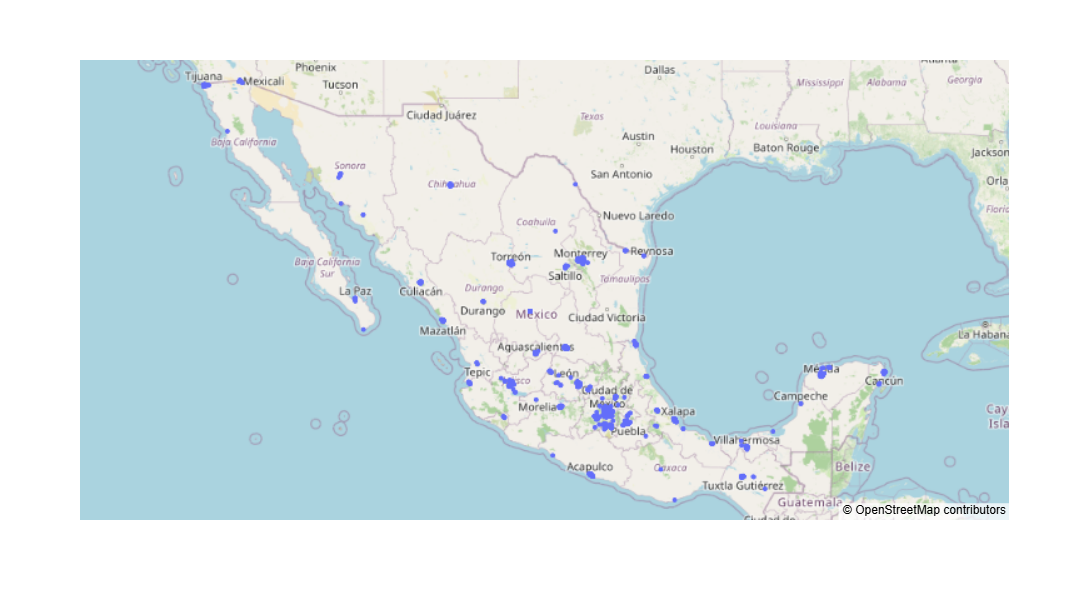

In [12]:
# Use plotly express to create figure
fig = px.scatter_map(
    df,  # Our DataFrame
    lat="lat",  
    lon="lon", 
    width=600,  # Width of map
    height=600,  # Height of map
    hover_data=["price_usd"],  # Display price when hovering mouse over house
    map_style="open-street-map"
)

# Show figure
fig.show()

In [13]:
# Get value counts of "state" column
df["state"].value_counts().head(10)

state
Distrito Federal                   303
Estado de México                   179
Yucatán                            171
Morelos                            160
Querétaro                          128
Veracruz de Ignacio de la Llave    117
Puebla                              95
Nuevo León                          83
Jalisco                             60
Chiapas                             55
Name: count, dtype: int64

In [14]:
# Describe "area_m2", "price_usd" columns
df[["area_m2", "price_usd"]].describe()

,area_m2,price_usd
count,1736.000000,1736.000000
mean,170.261521,115331.980766
std,80.594539,65426.173873
min,60.000000,33157.890000
25%,101.750000,65789.470000
50%,156.000000,99262.130000
75%,220.000000,150846.665000
max,385.000000,326733.660000


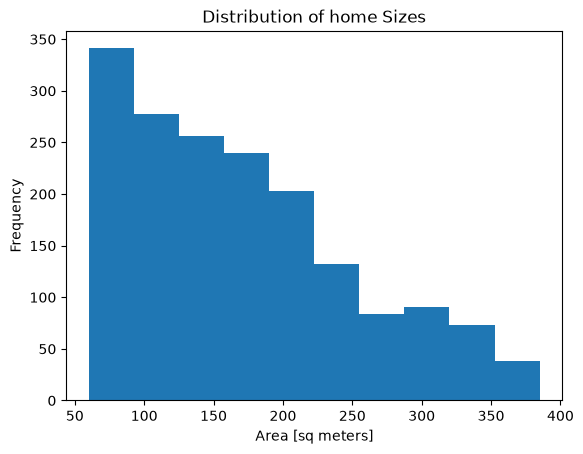

In [15]:
plt.hist(df["area_m2"])
plt.xlabel("Area [sq meters]")
plt.ylabel("Frequency")
plt.title("Distribution of Home Sizes");


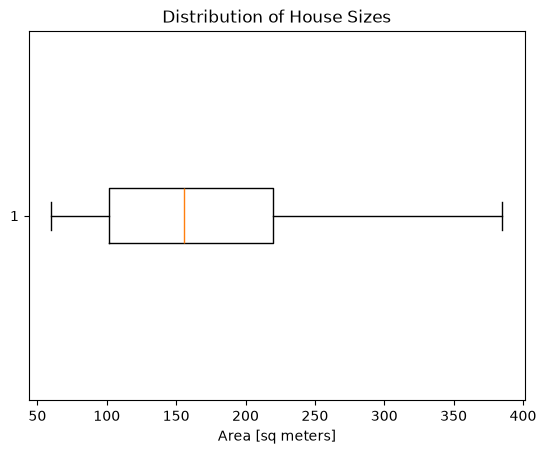

In [16]:
plt.boxplot(df["area_m2"], orientation="horizontal")
plt.xlabel("Area [sq meters]")
plt.title("Distribution of Home Sizes");


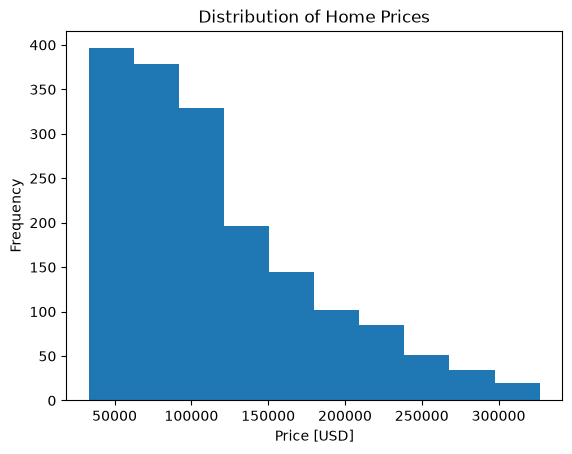

In [17]:
plt.hist(df["price_usd"])
plt.xlabel("Price [USD]")
plt.ylabel("Frequency")
plt.title("Distribution of Home Prices");

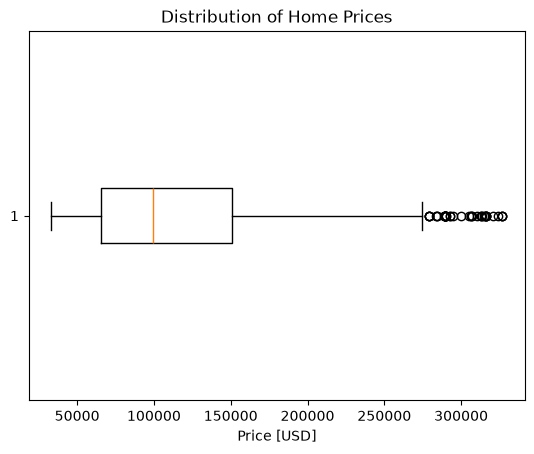

In [18]:
plt.boxplot(df["price_usd"], orientation="horizontal")
plt.xlabel("Price [USD]")
plt.title("Distribution of Home Prices");

### Location vs. Size: What Influences House Prices in Mexico?

**Which state has the most expensive real estate market?**  


In [19]:
# Create "price_per_m2" column
df["price_per_m2"] = df["price_usd"]/df["area_m2"]

print("df shape:", df.shape)
df.head()

df shape: (1736, 7)


,property_type,state,lat,lon,area_m2,price_usd,price_per_m2
0,house,Estado de México,19.560181,-99.233528,150.0,67965.56,453.103733
1,house,Nuevo León,25.688436,-100.198807,186.0,63223.78,339.912796
2,apartment,Guerrero,16.767704,-99.764383,82.0,84298.37,1028.028902
3,apartment,Guerrero,16.829782,-99.911012,150.0,94308.80,628.725333
5,house,Yucatán,21.052583,-89.538639,205.0,105191.37,513.128634


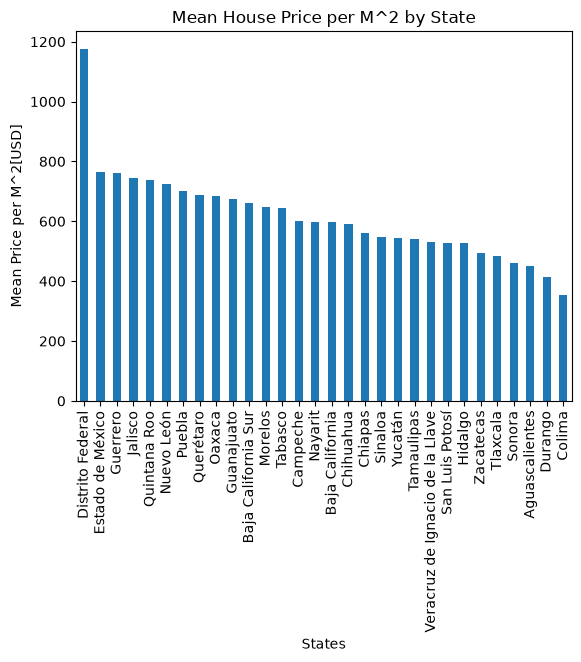

In [20]:
df.groupby("state")["price_per_m2"].mean().sort_values(ascending=False).plot(
    kind="bar",
    xlabel="States",
    ylabel="Mean Price per M^2[USD]",
    title="Mean House Price per M^2 by State"
);

**Is there a relationship between home size and price?**

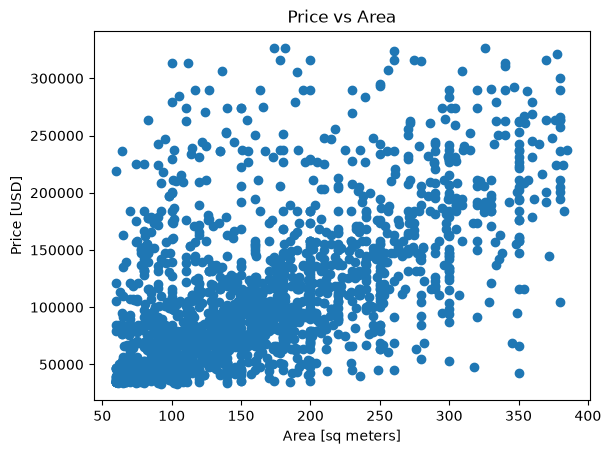

In [21]:
# Create scatter plot of "price_usd" vs "area_m2"
plt.scatter(x=df["area_m2"], y=df["price_usd"])
plt.xlabel("Area [sq meters]")
plt.ylabel("Price [USD]")
plt.title("Price vs Area");

In [22]:
# Calculate correlation of "price_usd" and "area_m2"
p_correlation = df["area_m2"].corr(df["price_usd"])
print("Correlation of 'area_m2' and 'price_usd' (all Mexico):", p_correlation)

Correlation of 'area_m2' and 'price_usd' (all Mexico): 0.585518245323206


---
## Summary & Key Findings

- **Data Cleaning:** Harmonizing three raw CSV files (2,100 raw rows) produced **1,736 clean listings** with mean area `170.26 m²` (median `156.00 m²`) and mean price `$115,331.98`.
- **Regional Disparities:** Listings concentrate around major metropolitan centres (led by Distrito Federal with 303 listings). Distrito Federal commands the highest unit price at nearly **`$1,180/m²`**, well above second-tier states (`$720–$765/m²`) and lower-cost markets like Durango and Colima (`<$420/m²`).
- **Size-Price Relationship:** National Pearson correlation between `area_m2` and `price_usd` is **`r = 0.5855`**, showing a clear positive trend—but price variance widens noticeably for homes above `150 m²`.
- **Next Step:** Because neither floor area nor location alone fully explains residential pricing, Project 2 builds a multivariate regression pipeline combining structural size, coordinates, and neighbourhood categories.
